# Análise do desempenho comercial e oportunidades de crescimento das categorias de produtos no ecossistema Olist

##Introdução

1. Contexto do projeto

Este projeto analisa o desempenho comercial das categorias de produtos presentes no Brazilian E-Commerce Public Dataset by Olist, com o objetivo de identificar segmentos que apresentam crescimento do valor comercializado superior ao crescimento geral do ecossistema, combinado com bons indicadores de satisfação dos consumidores.
A análise busca identificar categorias com indicadores promissores de desempenho comercial, considerando crescimento, escala de vendas e avaliações dos consumidores.

2. Pergunta de negócio

Quais categorias de produtos apresentam crescimento de valor comercializado acima do crescimento geral e mantêm bons níveis de satisfação dos clientes?

3. Objetivos da análise

- Analisar a evolução do e-commerce no período disponível.
- Identificar as categorias com maior crescimento de valor comercializado.
- Avaliar a satisfação dos clientes.
- Identificar categorias com indicadores promissores para oportunidades de expansão.

4. Fonte de dados

Brazilian E-Commerce Public Dataset by Olist — conjunto de dados públicos e anonimizados, com informações de pedidos, produtos, vendedores, pagamentos e avaliações. Este projeto utilizará especificamente dados de pedidos, itens, produtos e avaliações, com apoio da tabela de vendedores para a verificação de integridade.

5. Metodologia

Foram considerados pedidos com status delivered, e data de compra entre janeiro de 2017 a junho de 2018.

A comparação de valor comercializado para cálculo de crescimento utiliza semestres equivalentes, para minimizar o impacto de sazonalidades no resultado da análise. Dessa forma, foram comparados os dados do primeiro semestre de 2018 com o primeiro semestre de 2017.

## Upload e Conferência dos Dados

In [132]:
# manipulação dos dados
import pandas as pd
import numpy as np

# visualização dos dados
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

# Paleta de cores
AZUL = '#024F7F'
AZUL_MEDIO = '#39799F'
TURQUESA = '#8BC1BC'

PRETO = '#262626'
CINZA = '#A6A6A6'
CINZA_CLARO = '#EAEAEA'
BRANCO = '#FFFFFF'

# Baixar a fonte Open Sans
!wget -q -O /content/OpenSans.ttf \
"https://raw.githubusercontent.com/google/fonts/main/ofl/opensans/OpenSans%5Bwdth%2Cwght%5D.ttf"

# Registrar a fonte no Matplotlib
import matplotlib.font_manager as fm

fm.fontManager.addfont('/content/OpenSans.ttf')

# Configurações globais dos gráficos
plt.rcParams.update({

    # Dimensões e fundo
    'figure.figsize': (10, 5.625),
    'figure.facecolor': BRANCO,
    'axes.facecolor': BRANCO,

    # Fonte
    'font.family': 'Open Sans',
    'font.size': 10,

    # Títulos
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.titlecolor': PRETO,

    # Textos e rótulos
    'axes.labelsize': 10,
    'axes.labelcolor': '#666666',
    'text.color': PRETO,

    # Eixos
    'xtick.color': '#666666',
    'ytick.color': '#666666',

    # Remover bordas
    'axes.edgecolor': BRANCO,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.spines.left': False,
    'axes.spines.bottom': False,

    # Remover grid
    'axes.grid': False,

    # Exportação
    'savefig.facecolor': BRANCO,
    'savefig.dpi': 220
})

In [133]:
# Leitura dos arquivos

order_items = pd.read_csv('olist_order_items_dataset.csv')
reviews = pd.read_csv('olist_order_reviews_dataset.csv')
orders = pd.read_csv('olist_orders_dataset.csv')
products = pd.read_csv('olist_products_dataset.csv')
sellers = pd.read_csv('olist_sellers_dataset.csv')

In [134]:
# Conferência inicial

tabelas = {
'orders': orders,
'order_items': order_items,
'products': products,
'sellers': sellers,
'reviews': reviews,
}
for nome, tabela_atual in tabelas.items():
  print(nome, 'head\n', tabela_atual.head(), '\n')
  print(nome, 'shape\n', tabela_atual.shape, '\n')
  print(nome, '\n')
  tabela_atual.info()
  print('\n')
  print(nome, 'describe\n', tabela_atual.describe(), '\n')

orders head
                            order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp    order_approved_at  \
0    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37  2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49  2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06  2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39  2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00     

In [135]:
# Conferência de duplicidades

print("Pedidos duplicados:")
print(orders['order_id'].duplicated().sum())

print("\nProdutos duplicados:")
print(products['product_id'].duplicated().sum())

print("\nVendedores duplicados:")
print(sellers['seller_id'].duplicated().sum())

print("\nItens duplicados pela combinação pedido + item:")
print(order_items.duplicated(
    subset=['order_id', 'order_item_id']
).sum())

print("\nAvaliações duplicadas pelo ID:")
print(reviews['review_id'].duplicated().sum())

Pedidos duplicados:
0

Produtos duplicados:
0

Vendedores duplicados:
0

Itens duplicados pela combinação pedido + item:
0

Avaliações duplicadas pelo ID:
814


In [136]:
# Conferência de relações entre tabelas e ausência de dados

# Verificar se todos os pedidos dos itens existem em orders

pedidos_sem_correspondencia = (
    ~order_items['order_id'].isin(orders['order_id'])
).sum()

# Verificar se todos os produtos dos itens existem em products

produtos_sem_correspondencia = (
    ~order_items['product_id'].isin(products['product_id'])
).sum()

# Verificar se todos os vendedores dos itens existem em sellers

vendedores_sem_correspondencia = (
    ~order_items['seller_id'].isin(sellers['seller_id'])
).sum()

print("Itens sem pedido correspondente:", pedidos_sem_correspondencia)
print("Itens sem produto correspondente:", produtos_sem_correspondencia)
print("Itens sem vendedor correspondente:", vendedores_sem_correspondencia)

# Verificar quantidade e percentual de valores ausentes em products

ausentes_produtos = pd.DataFrame({
    'quantidade_ausente': products.isna().sum(),
    'percentual_ausente': (
        products.isna().mean() * 100
    ).round(2)
})

display(ausentes_produtos)

# Quantidade de produtos sem categoria

print(
    "Produtos sem categoria:",
    products['product_category_name'].isna().sum()
)

# Quantidade de categorias distintas

print(
    "Categorias distintas:",
    products['product_category_name'].nunique()
)

Itens sem pedido correspondente: 0
Itens sem produto correspondente: 0
Itens sem vendedor correspondente: 0


,quantidade_ausente,percentual_ausente
product_id,0,0.00
product_category_name,610,1.85
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


Produtos sem categoria: 610
Categorias distintas: 73


In [137]:
# Verificar reviews duplicados

# Identificar todas as linhas que possuem review_id repetido

reviews_duplicadas = reviews[
    reviews.duplicated(
        subset='review_id',
        keep=False
    )
].sort_values('review_id')

print("Total de linhas envolvidas em duplicidades:",
      len(reviews_duplicadas))

print("Quantidade de review_id distintos duplicados:",
      reviews_duplicadas['review_id'].nunique())

display(reviews_duplicadas.head(20))

# Verificar se existem linhas completamente duplicadas

print(
    "Linhas completamente duplicadas:",
    reviews.duplicated().sum()
)

# Verificar quantos pedidos possuem mais de um review_id

print(
    "Pedidos com mais de uma avaliação:",
    reviews['order_id'].duplicated().sum()
)

Total de linhas envolvidas em duplicidades: 1603
Quantidade de review_id distintos duplicados: 789


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
46678,00130cbe1f9d422698c812ed8ded1919,dfcdfc43867d1c1381bfaf62d6b9c195,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
29841,00130cbe1f9d422698c812ed8ded1919,04a28263e085d399c97ae49e0b477efa,1,NaN,"O cartucho ""original HP"" 60XL não é reconhecid...",2018-03-07 00:00:00,2018-03-20 18:08:23
90677,0115633a9c298b6a98bcbe4eee75345f,78a4201f58af3463bdab842eea4bc801,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
63193,0115633a9c298b6a98bcbe4eee75345f,0c9850b2c179c1ef60d2855e2751d1fa,5,NaN,NaN,2017-09-21 00:00:00,2017-09-26 03:27:47
92876,0174caf0ee5964646040cd94e15ac95e,f93a732712407c02dce5dd5088d0f47b,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
57280,0174caf0ee5964646040cd94e15ac95e,74db91e33b4e1fd865356c89a61abf1f,1,NaN,Produto entregue dentro de embalagem do fornec...,2018-03-07 00:00:00,2018-03-08 03:00:53
54832,017808d29fd1f942d97e50184dfb4c13,8daaa9e99d60fbba579cc1c3e3bfae01,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
99167,017808d29fd1f942d97e50184dfb4c13,b1461c8882153b5fe68307c46a506e39,5,NaN,NaN,2018-03-02 00:00:00,2018-03-05 01:43:30
20621,0254bd905dc677a6078990aad3331a36,5bf226cf882c5bf4247f89a97c86f273,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44
96080,0254bd905dc677a6078990aad3331a36,331b367bdd766f3d1cf518777317b5d9,1,NaN,O pedido consta de 2 produtos e até agora rece...,2017-09-09 00:00:00,2017-09-13 09:52:44


Linhas completamente duplicadas: 0
Pedidos com mais de uma avaliação: 551


## Tratamento dos dados

In [138]:
# Preencher categorias ausentes

products_tratado = products.copy()

# Tratar categorias sem identificação
products_tratado['product_category_name'] = (
    products_tratado['product_category_name'].fillna('Sem categoria')
)

# Dicionário com ajustes de nomenclatura
nomes_categorias = {
    'beleza_saude': 'Beleza e Saúde',
    'cama_mesa_banho': 'Cama, Mesa e Banho',
    'moveis_decoracao': 'Móveis e Decoração',
    'informatica_acessorios': 'Informática e Acessórios',
    'esporte_lazer': 'Esporte e Lazer',
    'utilidades_domesticas': 'Utilidades Domésticas',
    'ferramentas_jardim': 'Ferramentas e Jardim',
    'relogios_presentes': 'Relógios e Presentes',
    'bebes': 'Bebês',
    'eletrodomesticos': 'Eletrodomésticos',
    'eletroportateis': 'Eletroportáteis',
    'livros_tecnicos': 'Livros Técnicos',
    'instrumentos_musicais': 'Instrumentos Musicais',
    'artigos_de_festas': 'Artigos de Festa',
    'alimentos_bebidas': 'Alimentos e Bebidas',
    'casa_construcao': 'Casa e Construção',
    'fashion_bolsas_e_acessorios': 'Moda, Bolsas e Acessórios',
    'malas_acessorios': 'Malas e Acessórios',
    'moveis_quarto': 'Móveis para Quarto',
    'moveis_sala': 'Móveis para Sala',
    'moveis_escritorio': 'Móveis de Escritório',
    'cool_stuff': 'Produtos Diferenciados',
    'pet_shop': 'Pet Shop',
    'agro_industria_e_comercio': 'Agroindústria e Comércio',
    'audio': 'Áudio',
    'climatizacao': 'Climatização',
    'telefonia_fixa': 'Telefonia Fixa',
    'construcao_ferramentas_construcao': 'Construção e Ferramentas',
    'construcao_ferramentas_seguranca': 'Ferramentas de Segurança',
    'construcao_ferramentas_ferramentas': 'Ferramentas',
    'cine_foto': 'Câmeras e Fotografia',
    'dvds_blu_ray': 'DVDs e Blu-ray',
    'cds_dvds_musicais': 'CDs e DVDs Musicais',
    'artes_e_artesanato': 'Artes e Artesanato',
    'eletrodomesticos_2': 'Eletrodomésticos — Outros'
}

# Criar nome formatado automaticamente
products_tratado['product_category_name_formatada'] = (
    products_tratado['product_category_name']
    .str.replace('_', ' ')
    .str.title()
)

# Aplicar os nomes personalizados
products_tratado['product_category_name_formatada'] = (
    products_tratado['product_category_name']
    .map(nomes_categorias)
    .fillna(products_tratado['product_category_name_formatada'])
)

# Preservar a categoria sem identificação
products_tratado.loc[
    products_tratado['product_category_name'] == 'Sem categoria',
    'product_category_name_formatada'
] = 'Sem categoria'

print("Categorias ausentes:", products_tratado['product_category_name'].isna().sum())

print(
    "Produtos sem categoria:",
    (products_tratado['product_category_name'] == 'Sem categoria').sum()
)

Categorias ausentes: 0
Produtos sem categoria: 610


In [139]:
# Filtrar somente pedidos entregues (foco da análise)

orders_tratado = orders.copy()

orders_tratado['order_purchase_timestamp'] = pd.to_datetime(
    orders_tratado['order_purchase_timestamp']
)

orders_tratado = orders_tratado[
    orders_tratado['order_status'] == 'delivered'
].copy()

display(orders_tratado.head())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [140]:
# Retirar review_id duplicado somente quando for para o mesmo order_id

# Manter uma review_id por pedido, que depois será vinculada às categorias presentes em cada pedido

reviews_tratado = reviews.copy()

reviews_tratado = reviews_tratado.drop_duplicates(
    subset=['order_id', 'review_id']
)

reviews_tratado = (
    reviews_tratado.groupby('order_id', as_index=False)
    .agg(
        review_score=('review_score', 'mean')
    )
)

display(reviews_tratado.head())

,order_id,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,5.0
1,00018f77f2f0320c557190d7a144bdd3,4.0
2,000229ec398224ef6ca0657da4fc703e,5.0
3,00024acbcdf0a6daa1e931b038114c75,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,5.0


In [141]:
# Integração das bases de dados

base_analitica = order_items.merge(
    orders_tratado[
        ['order_id', 'order_purchase_timestamp']
    ],
    on='order_id',
    how='inner',
    validate='many_to_one'
)

base_analitica = base_analitica.merge(
    products_tratado[
        [
            'product_id',
            'product_category_name',
            'product_category_name_formatada'
        ]
    ],
    on='product_id',
    how='left',
    validate='many_to_one'
)

base_analitica = base_analitica.merge(
    reviews_tratado,
    on='order_id',
    how='left',
    validate='many_to_one'
)

# Conferência da base integrada

print("Dimensões da base analítica:", base_analitica.shape)

print("Quantidade de pedidos:", base_analitica['order_id'].nunique())

print("Quantidade de produtos:", base_analitica['product_id'].nunique())

print("Quantidade de categorias:", base_analitica['product_category_name'].nunique())

print("Categorias ausentes:", base_analitica['product_category_name'].isna().sum())

print("Avaliações ausentes:", base_analitica['review_score'].isna().sum())

display(base_analitica.head())

Dimensões da base analítica: (110197, 11)
Quantidade de pedidos: 96478
Quantidade de produtos: 32216
Quantidade de categorias: 74
Categorias ausentes: 0
Avaliações ausentes: 827


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value,order_purchase_timestamp,product_category_name,product_category_name_formatada,review_score
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29,2017-09-13 08:59:02,cool_stuff,Produtos Diferenciados,5.0
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93,2017-04-26 10:53:06,pet_shop,Pet Shop,4.0
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87,2018-01-14 14:33:31,moveis_decoracao,Móveis e Decoração,5.0
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79,2018-08-08 10:00:35,perfumaria,Perfumaria,4.0
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14,2017-02-04 13:57:51,ferramentas_jardim,Ferramentas e Jardim,5.0


Após o cruzamento das bases, foi obtida uma base analítica com 110.197 registros e 11 colunas, contemplando 96.478 pedidos distintos, 32.216 produtos e 74 categorias. O processo preservou a granularidade dos itens comercializados e permitiu integrar informações de pedidos, produtos e avaliações. Foram identificados 827 registros sem avaliação associada, que serão desconsiderados nos cálculos de satisfação, sem necessidade de exclusão da base analítica.

## Análise dos dados


### Qual foi a evolução comercial do ecossistema?


In [142]:
# Indicadores mensais

# Será utilizado somente o período entre jan/2017 e jun/2018 para análise semestral de crescimento.
# A base de pedidos de 2016 pode distorcer resultados, devido à ausência de pedidos entregues em nov/2016


base_analise = base_analitica[
    (base_analitica['order_purchase_timestamp'] >= '2017-01-01') &
    (base_analitica['order_purchase_timestamp'] < '2018-07-01')
].copy()

base_analise['ano'] = (
    base_analise['order_purchase_timestamp'].dt.year
)

base_analise['mes'] = (
    base_analise['order_purchase_timestamp'].dt.month
)

base_analise['ano_mes'] = (
    base_analise['order_purchase_timestamp'].dt.to_period('M')
)


evolucao_ecossistema = (
    base_analise.groupby('ano_mes')
    .agg(
        valor_comercializado=('price', 'sum'),
        quantidade_pedidos=('order_id', 'nunique')
    )
    .reset_index()
)

evolucao_ecossistema['ano_mes'] = (
    evolucao_ecossistema['ano_mes'].astype(str)
)

display(evolucao_ecossistema.head())


,ano_mes,valor_comercializado,quantidade_pedidos
0,2017-01,111798.36,750
1,2017-02,234223.40,1653
2,2017-03,359198.85,2546
3,2017-04,340669.68,2303
4,2017-05,489338.25,3546


In [143]:
# Crescimento por semestre

# Criar identificação do semestre
base_analise['ano'] = base_analise['order_purchase_timestamp'].dt.year
base_analise['semestre'] = (
    base_analise['order_purchase_timestamp'].dt.month
    .apply(lambda mes: 1 if mes <= 6 else 2)
)

# Somar o valor comercializado por semestre
desempenho_semestral = (
    base_analise.groupby(['ano', 'semestre'])
    .agg(
        valor_comercializado=('price', 'sum'),
        quantidade_pedidos=('order_id', 'nunique')
    )
    .reset_index()
)

desempenho_semestral['periodo'] = (
    desempenho_semestral['semestre'].astype(str)
    + 'º semestre/'
    + desempenho_semestral['ano'].astype(str)
)

# Variação em relação ao semestre imediatamente anterior
desempenho_semestral['crescimento_vs_semestre_anterior'] = (
    desempenho_semestral['valor_comercializado'].pct_change() * 100
)

display(desempenho_semestral)

valor_1sem_2017 = desempenho_semestral.loc[
    (desempenho_semestral['ano'] == 2017) &
    (desempenho_semestral['semestre'] == 1),
    'valor_comercializado'
].iloc[0]

valor_1sem_2018 = desempenho_semestral.loc[
    (desempenho_semestral['ano'] == 2018) &
    (desempenho_semestral['semestre'] == 1),
    'valor_comercializado'
].iloc[0]

crescimento_1sem = (
    (valor_1sem_2018 - valor_1sem_2017) / valor_1sem_2017
) * 100

print(f'Crescimento do 1º semestre de 2017 para o 1º semestre de 2018: {crescimento_1sem:.2f}%')

,ano,semestre,valor_comercializado,quantidade_pedidos,periodo,crescimento_vs_semestre_anterior
0,2017,1,1957151.91,13933,1º semestre/2017,NaN
1,2017,2,4005750.10,29495,2º semestre/2017,104.672416
2,2018,1,5511595.02,40273,1º semestre/2018,37.592083


Crescimento do 1º semestre de 2017 para o 1º semestre de 2018: 181.61%


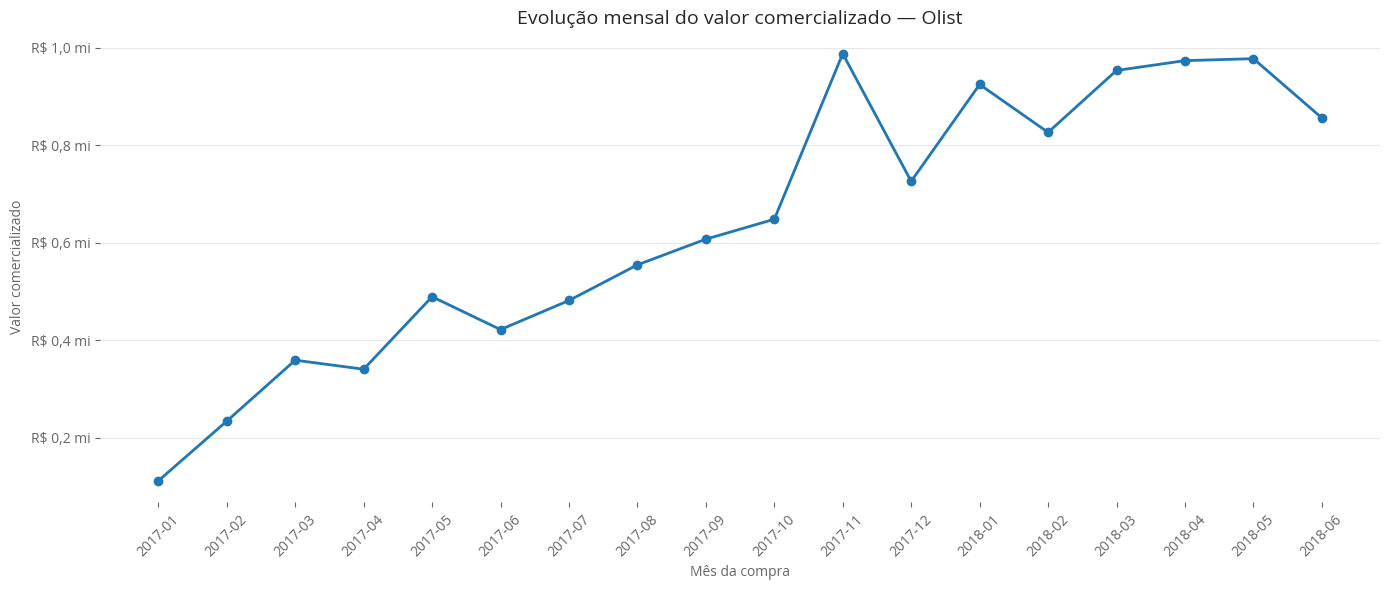

In [144]:
# Gráfico 1 - Evolução mensal do ecossistema

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import pandas as pd

# Agrupar o valor comercializado por mês
evolucao_ecossistema = (
    base_analise.groupby(
        base_analise['order_purchase_timestamp'].dt.to_period('M')
    )
    .agg(
        valor_comercializado=('price', 'sum'),
        quantidade_pedidos=('order_id', 'nunique')
    )
    .reset_index()
)

evolucao_ecossistema.columns = [
    'ano_mes',
    'valor_comercializado',
    'quantidade_pedidos'
]

# Garantir que todos os 18 meses estejam representados
meses = pd.period_range('2017-01', '2018-06', freq='M')

evolucao_ecossistema = (
    evolucao_ecossistema
    .set_index('ano_mes')
    .reindex(meses, fill_value=0)
    .rename_axis('ano_mes')
    .reset_index()
)

# Converter os períodos para texto para exibição
evolucao_ecossistema['ano_mes'] = (
    evolucao_ecossistema['ano_mes'].astype(str)
)

# Construir o gráfico
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    evolucao_ecossistema['ano_mes'],
    evolucao_ecossistema['valor_comercializado'],
    marker='o',
    linewidth=2
)

# Formatar valores em milhões de reais
ax.yaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda valor, pos: f'R$ {valor / 1_000_000:.1f} mi'.replace('.', ',')
    )
)

ax.set_title(
    'Evolução mensal do valor comercializado — Olist',
    fontsize=14
)

ax.set_xlabel('Mês da compra')
ax.set_ylabel('Valor comercializado')

ax.tick_params(axis='x', rotation=45)
ax.grid(axis='y', alpha=0.3)


plt.tight_layout()
plt.show()

### Quais categorias concentram o maior valor comercializado e qual é a participação de cada uma no ecossistema?

In [145]:
# Tabela de desempenho por categoria

desempenho_categorias = (
    base_analise.groupby('product_category_name_formatada')
    .agg(
        valor_comercializado=('price', 'sum'),
        quantidade_pedidos=('order_id', 'nunique'),
        quantidade_itens=('product_id', 'count')
    )
    .reset_index()
)

# Participação de cada categoria no valor comercializado total
desempenho_categorias['participacao_percentual'] = (
    desempenho_categorias['valor_comercializado']
    / desempenho_categorias['valor_comercializado'].sum()
) * 100

# Ordenar da maior para a menor categoria
desempenho_categorias = desempenho_categorias.sort_values(
    'valor_comercializado',
    ascending=False
)

display(desempenho_categorias.head(15))

,product_category_name_formatada,valor_comercializado,quantidade_pedidos,quantidade_itens,participacao_percentual
10,Beleza e Saúde,1006642.27,7146,7817,8.772866
65,Relógios e Presentes,998534.06,4597,4923,8.702203
13,"Cama, Mesa e Banho",907659.45,8201,9673,7.910233
28,Esporte e Lazer,847964.33,6671,7483,7.389991
41,Informática e Acessórios,806939.64,5757,6799,7.032462
54,Móveis e Decoração,619675.03,5574,7229,5.400455
64,Produtos Diferenciados,572211.10,3323,3477,4.986808
72,Utilidades Domésticas,492994.96,4723,5603,4.296441
7,Automotivo,489339.02,3133,3421,4.264579
11,Brinquedos,433234.23,3483,3687,3.775627


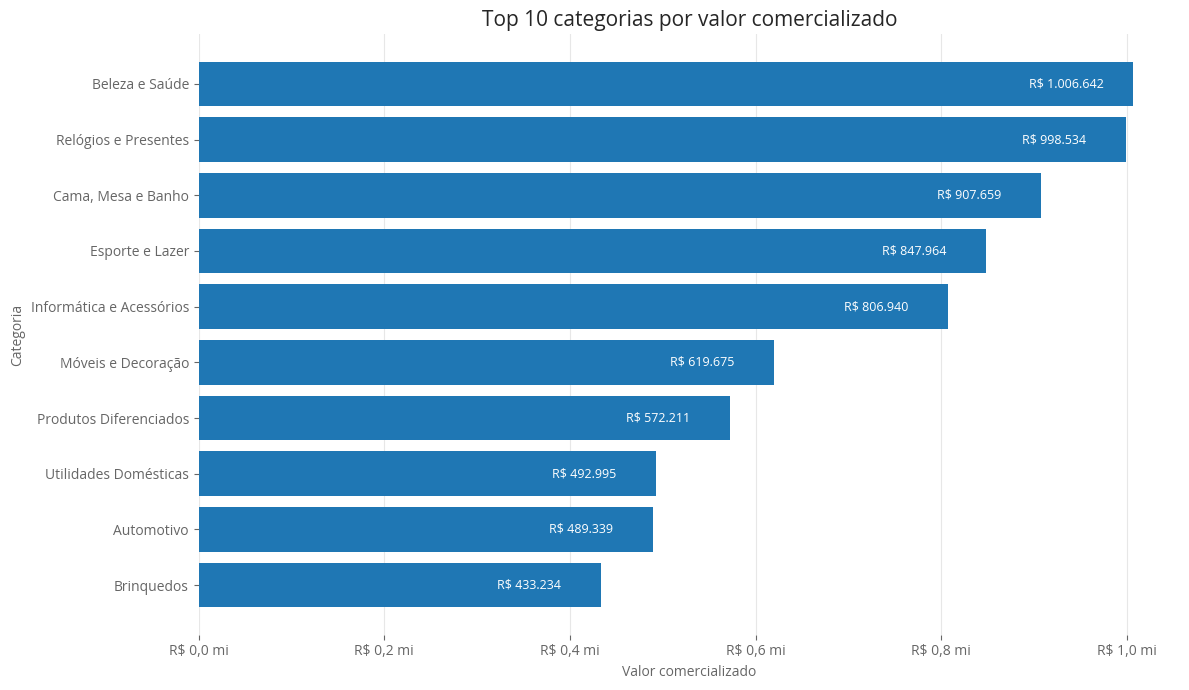

In [146]:
# Gráfico das categorias com maior valor comercializado

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

top_10_valor = (
    desempenho_categorias[
        desempenho_categorias['product_category_name_formatada'] != 'Sem categoria'
    ]
    .head(10)
    .sort_values('valor_comercializado')
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    top_10_valor['product_category_name_formatada'],
    top_10_valor['valor_comercializado']
)

# Rótulos dentro das barras
ax.bar_label(
    barras,
    labels=[
        f'R$ {valor:,.0f}'.replace(',', '.')
        for valor in top_10_valor['valor_comercializado']
    ],
    label_type='edge',
    padding=-75,
    color='white',
    fontsize=9,
    fontweight='bold'
)

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(
        lambda valor, pos: f'R$ {valor / 1_000_000:.1f} mi'.replace('.', ',')
    )
)

ax.set_title('Top 10 categorias por valor comercializado')
ax.set_xlabel('Valor comercializado')
ax.set_ylabel('Categoria')

ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

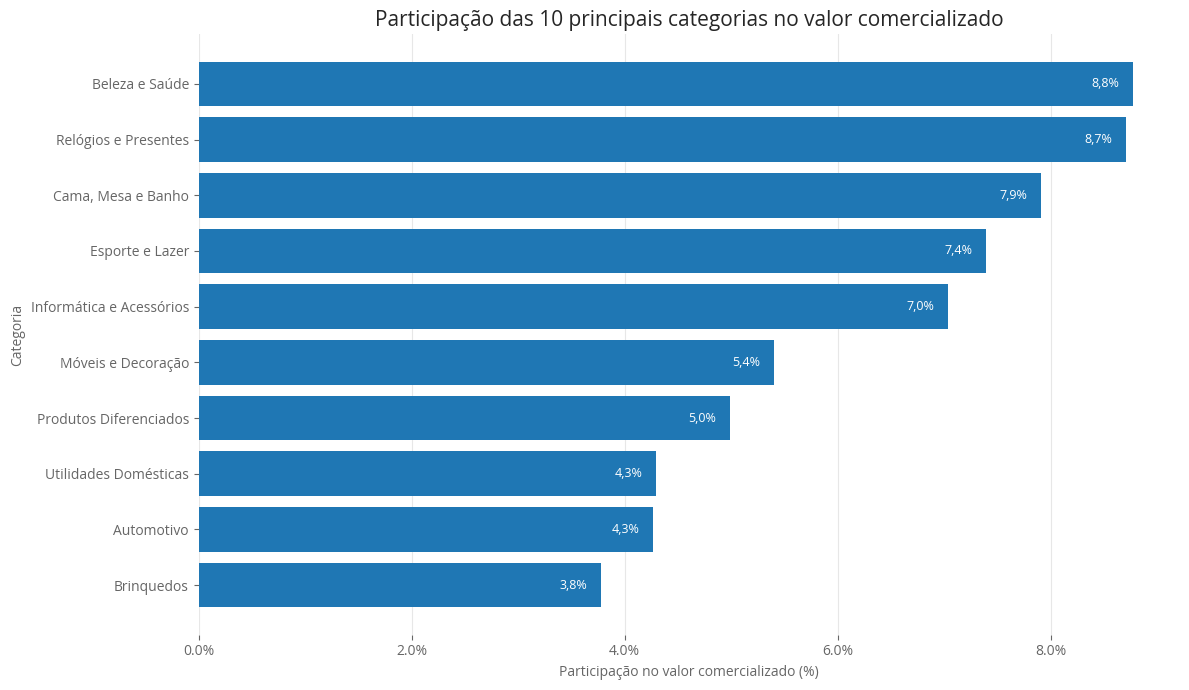

In [147]:
# Gráfico de participação no ecossistema

top_10_participacao = (
    desempenho_categorias[
        desempenho_categorias['product_category_name_formatada'] != 'Sem categoria'
    ]
    .head(10)
    .sort_values('participacao_percentual')
)

fig, ax = plt.subplots(figsize=(12, 7))

barras = ax.barh(
    top_10_participacao['product_category_name_formatada'],
    top_10_participacao['participacao_percentual']
)

ax.bar_label(
    barras,
    labels=[
        f'{valor:.1f}%'.replace('.', ',')
        for valor in top_10_participacao['participacao_percentual']
    ],
    label_type='edge',
    padding=-30,
    color='white',
    fontsize=9,
    fontweight='bold'
)

ax.xaxis.set_major_formatter(
    mticker.PercentFormatter(xmax=100, decimals=1)
)

ax.set_title('Participação das 10 principais categorias no valor comercializado')
ax.set_xlabel('Participação no valor comercializado (%)')
ax.set_ylabel('Categoria')

ax.grid(axis='x', alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

### Quais categorias estão puxando o crescimento comercial do ecossistema?

Nesta etapa serão identificadas as categorias com crescimento semestral acima do crescimento de valor comercializado do ecossistema

In [148]:
# Preparação da base por semestre

base_analise['semestre'] = np.where(
    base_analise['mes'] <= 6,
    '1º semestre',
    '2º semestre'
)

base_analise['periodo_semestre'] = (
    base_analise['ano'].astype(str)
    + ' - '
    + base_analise['semestre']
)

# Indicadores por categoria

desempenho_categorias = (
    base_analise
    .groupby('product_category_name_formatada')
    .agg(
        valor_comercializado=('price', 'sum'),
        quantidade_pedidos=('order_id', 'nunique'),
        quantidade_itens=('product_id', 'count')
    )
    .reset_index()
    .sort_values(
        'valor_comercializado',
        ascending=False
    )
)

# Comparativo de desempenho das categorias por semestre

valor_por_categoria_semestre = (
    base_analise
    .groupby([
        'product_category_name_formatada',
        'periodo_semestre'
    ])
    .agg(
        valor_comercializado=('price', 'sum')
    )
    .reset_index()
)

comparacao_categorias = (
    valor_por_categoria_semestre
    .pivot(
        index='product_category_name_formatada',
        columns='periodo_semestre',
        values='valor_comercializado'
    )
    .fillna(0)
    .reset_index()
)

# Períodos de referência - Reduzindo impacto de sazonalidade no segundo semestre

comparacao_categorias['crescimento_percentual'] = np.where(
    comparacao_categorias['2017 - 1º semestre'] > 0,
    (
        comparacao_categorias['2018 - 1º semestre']
        / comparacao_categorias['2017 - 1º semestre'] - 1
    ) * 100,
    np.nan
)

# Ordenar por maior valor

comparacao_categorias = comparacao_categorias.sort_values(
    '2018 - 1º semestre',
    ascending=False
)

comparacao_categorias.head(15)

periodo_semestre,product_category_name_formatada,2017 - 1º semestre,2017 - 2º semestre,2018 - 1º semestre,crescimento_percentual
10,Beleza e Saúde,160252.02,313580.98,532809.27,232.482093
65,Relógios e Presentes,131264.49,344346.22,522923.35,298.373810
13,"Cama, Mesa e Banho",135077.23,355519.69,417062.53,208.758575
41,Informática e Acessórios,142628.58,249157.71,415153.35,191.073044
28,Esporte e Lazer,139480.73,296193.41,412290.19,195.589355
54,Móveis e Decoração,113234.57,211353.03,295087.43,160.598358
72,Utilidades Domésticas,83855.17,138662.99,270476.80,222.552324
7,Automotivo,92438.02,142112.07,254788.93,175.632180
9,Bebês,33376.75,115058.13,207515.10,521.735490
64,Produtos Diferenciados,131388.40,250025.90,190796.80,45.215864


A categoria Bebês chama bastante atenção: passou de RS 33,4 mil para RS 207,5 mil. É um crescimento expressivo, mas seu valor comercializado ainda é inferior ao das principais categorias.

#### A categoria está crescendo e também ganhando share dentro do ecossistema?

In [149]:
participacao_semestre = (
    base_analise
    .groupby([
        'product_category_name_formatada',
        'periodo_semestre'
    ])
    .agg(
        valor_comercializado=('price', 'sum')
    )
    .reset_index()
)

participacao_semestre['total_semestre'] = (
    participacao_semestre
    .groupby('periodo_semestre')['valor_comercializado']
    .transform('sum')
)

participacao_semestre['participacao_percentual'] = (
    participacao_semestre['valor_comercializado']
    / participacao_semestre['total_semestre']
) * 100

participacao_categorias = (
    participacao_semestre
    .pivot(
        index='product_category_name_formatada',
        columns='periodo_semestre',
        values='participacao_percentual'
    )
    .reset_index()
)

participacao_categorias['variacao_participacao_pp'] = (
    participacao_categorias['2018 - 1º semestre']
    - participacao_categorias['2017 - 1º semestre']
)

participacao_categorias.sort_values(
    'variacao_participacao_pp',
    ascending=False
).head(15)

participacao_categorias_formatada = participacao_categorias.copy()

colunas_percentuais = [
    '2017 - 1º semestre',
    '2017 - 2º semestre',
    '2018 - 1º semestre',
    'variacao_participacao_pp'
]

for coluna in colunas_percentuais:
    participacao_categorias_formatada[coluna] = (
        participacao_categorias_formatada[coluna]
        .fillna(0)
        .map(lambda x: f'{x:.2f}%'.replace('.', ','))
    )

participacao_categorias_formatada.sort_values(
    'variacao_participacao_pp',
    ascending=False
).head(15)


periodo_semestre,product_category_name_formatada,2017 - 1º semestre,2017 - 2º semestre,2018 - 1º semestre,variacao_participacao_pp
65,Relógios e Presentes,"6,71%","8,60%","9,49%","2,78%"
9,Bebês,"1,71%","2,87%","3,77%","2,06%"
21,Construção e Ferramentas,"0,04%","0,46%","1,54%","1,49%"
10,Beleza e Saúde,"8,19%","7,83%","9,67%","1,48%"
25,Eletrodomésticos — Outros,"0,29%","0,38%","1,21%","0,92%"
62,Portateis Casa Forno E Cafe,"0,00%","0,02%","0,69%","0,69%"
13,"Cama, Mesa e Banho","6,90%","8,88%","7,57%","0,67%"
72,Utilidades Domésticas,"4,28%","3,46%","4,91%","0,62%"
57,Papelaria,"1,20%","1,70%","1,81%","0,61%"
24,Eletrodomésticos,"0,31%","0,43%","0,80%","0,50%"


Destaques:

- Relógios e Presentes: participação de 6,71% para 9,49%, um ganho de 2,78 pontos percentuais. A categoria combina crescimento comercial expressivo (+298,37%) com ganho de participação.
- Bebês: ganhou 2,06 p.p. e cresceu 521,74% em valor comercializado. É uma categoria em expansão acelerada, embora ainda tenha uma participação menor (3,77%).
- Construção e Ferramentas: ganhou 1,49 p.p., saindo de uma participação praticamente residual (0,04%) para 1,54%. É um crescimento interessante, mas com base inicial muito pequena.
- Beleza e Saúde: ganhou 1,48 p.p. e chegou a 9,67%, tornando-se a categoria de maior participação entre as apresentadas.
- Eletrodomésticos — Outros: ganhou 0,92 p.p., chegando a 1,21%.

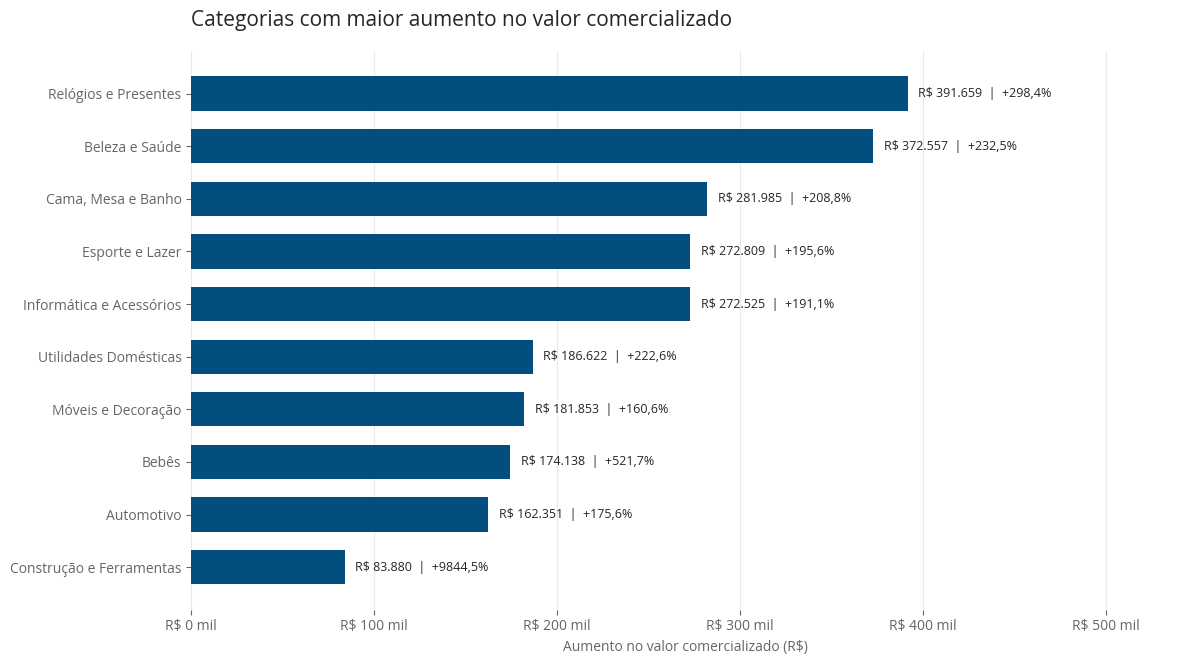

In [150]:
# Gráfico - Categorias com aumento no valor comercializado

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np

# Preparar os dados
crescimento_categorias = comparacao_categorias.copy()

crescimento_categorias = crescimento_categorias[
    crescimento_categorias['product_category_name_formatada'] != 'Sem categoria'
].copy()

crescimento_categorias['aumento_absoluto'] = (
    crescimento_categorias['2018 - 1º semestre']
    - crescimento_categorias['2017 - 1º semestre']
)

# Selecionar as 10 categorias com maior aumento em R$
top_crescimento = (
    crescimento_categorias
    .nlargest(10, 'aumento_absoluto')
    .sort_values('aumento_absoluto', ascending=True)
)

# Criar o gráfico
fig, ax = plt.subplots(figsize=(12, 6.75))

barras = ax.barh(
    top_crescimento['product_category_name_formatada'],
    top_crescimento['aumento_absoluto'],
    color='#024F7F',
    height=0.65
)

# Formatação dos valores
def formatar_reais(valor):
    return f'R$ {valor:,.0f}'.replace(',', '.')

def formatar_percentual(valor):
    if pd.isna(valor):
        return 'sem base comparável'
    return f'{valor:+.1f}%'.replace('.', ',')

# Rótulos ao lado das barras
for barra, (_, linha) in zip(barras, top_crescimento.iterrows()):
    valor = barra.get_width()
    percentual = formatar_percentual(linha['crescimento_percentual'])

    ax.text(
        valor + top_crescimento['aumento_absoluto'].max() * 0.015,
        barra.get_y() + barra.get_height() / 2,
        f'{formatar_reais(valor)}  |  {percentual}',
        va='center',
        fontsize=9,
        color='#262626'
    )

ax.set_title(
    'Categorias com maior aumento no valor comercializado',
    loc='left',
    pad=18,
    fontweight='bold'
)

ax.set_xlabel('Aumento no valor comercializado (R$)')
ax.set_ylabel('')

ax.xaxis.set_major_formatter(
    mticker.FuncFormatter(lambda x, pos: f'R$ {x/1000:.0f} mil')
)

ax.grid(axis='x', color='#EAEAEA', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines['bottom'].set_visible(False)

# Espaço para os rótulos
ax.set_xlim(
    0,
    top_crescimento['aumento_absoluto'].max() * 1.38
)

plt.tight_layout()
plt.show()


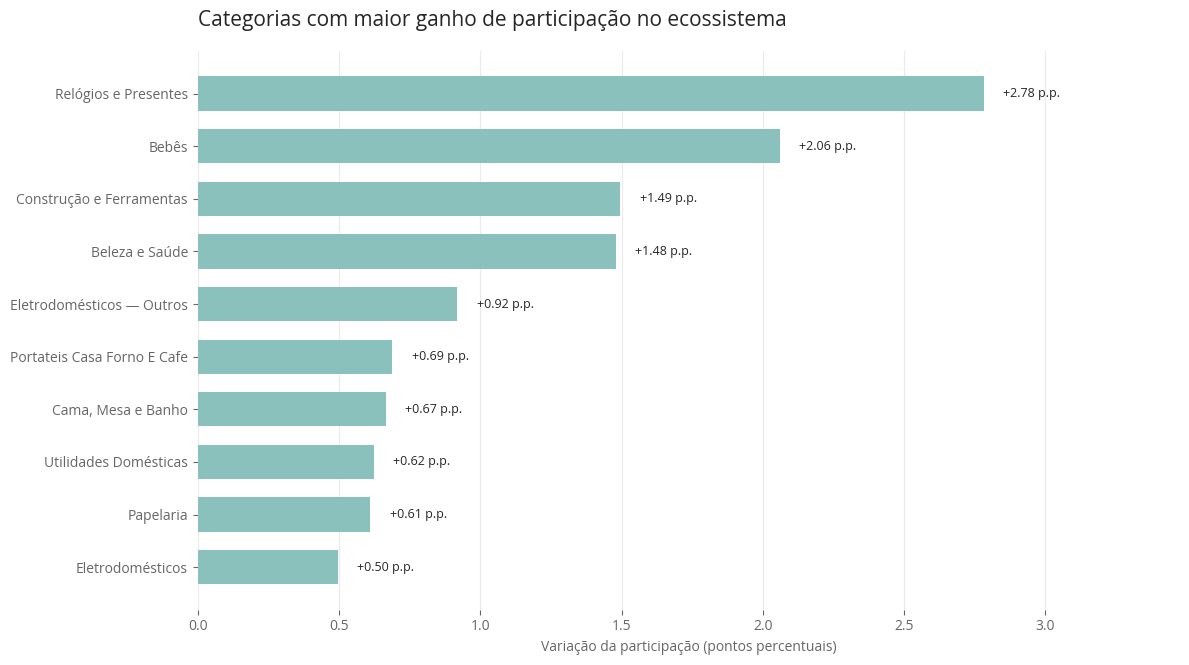

In [151]:
# Gráfico - Categorias com maior ganho de participação

# Preparar os dados
ganho_share = participacao_categorias.copy()

ganho_share = ganho_share[
    ganho_share['product_category_name_formatada'] != 'Sem categoria'
].copy()

# Selecionar as 10 categorias com maior ganho de participação
top_share = (
    ganho_share
    .nlargest(10, 'variacao_participacao_pp')
    .sort_values('variacao_participacao_pp', ascending=True)
)

# Criar o gráfico
fig, ax = plt.subplots(figsize=(12, 6.75))

barras = ax.barh(
    top_share['product_category_name_formatada'],
    top_share['variacao_participacao_pp'],
    color='#8BC1BC',
    height=0.65
)

# Rótulos das barras
for barra in barras:
    valor = barra.get_width()

    ax.text(
        valor + top_share['variacao_participacao_pp'].max() * 0.025,
        barra.get_y() + barra.get_height() / 2,
        f'+{valor:.2f} p.p.',
        va='center',
        fontsize=9,
        color='#262626'
    )

ax.set_title(
    'Categorias com maior ganho de participação no ecossistema',
    loc='left',
    pad=18,
    fontweight='bold'
)

ax.set_xlabel('Variação da participação (pontos percentuais)')
ax.set_ylabel('')

ax.grid(axis='x', color='#EAEAEA', linewidth=0.8)
ax.set_axisbelow(True)
ax.spines['bottom'].set_visible(False)

ax.set_xlim(
    0,
    top_share['variacao_participacao_pp'].max() * 1.25
)

plt.tight_layout()
plt.show()

### Qual o nível de satisfação dos pedidos por categoria de produto?


In [152]:
# Preparaçao da base de dados

base_satisfacao = (
    base_analise[
        base_analise['product_category_name_formatada'] != 'Sem categoria'
    ][
        ['order_id', 'product_category_name_formatada', 'review_score']
    ]
    .drop_duplicates(
        subset=['order_id', 'product_category_name_formatada']
    )
    .dropna(subset=['review_score'])
    .copy()
)

# Cálculo dos indicadores

satisfacao_categorias = (
    base_satisfacao
    .assign(
        avaliacao_negativa=lambda df: df['review_score'].isin([1, 2])
    )
    .groupby('product_category_name_formatada')
    .agg(
        nota_media=('review_score', 'mean'),
        pedidos_avaliados=('order_id', 'nunique'),
        percentual_avaliacoes_negativas=('avaliacao_negativa', 'mean')
    )
    .reset_index()
)

satisfacao_categorias['percentual_avaliacoes_negativas'] *= 100

satisfacao_categorias = satisfacao_categorias.sort_values(
    'nota_media', ascending=False
)

display(satisfacao_categorias.head(10))

,product_category_name_formatada,nota_media,pedidos_avaliados,percentual_avaliacoes_negativas
32,Fashion Roupa Infanto Juvenil,5.000000,7,0.000000
63,Portateis Cozinha E Preparadores De Alimentos,5.000000,2,0.000000
12,CDs e DVDs Musicais,4.666667,12,0.000000
45,Livros Interesse Geral,4.554273,433,5.773672
44,Livros Importados,4.545455,44,6.818182
4,Artes e Artesanato,4.500000,4,0.000000
30,Fashion Esporte,4.440000,25,8.000000
46,Livros Técnicos,4.420792,202,9.900990
2,Alimentos e Bebidas,4.405759,191,4.712042
47,Malas e Acessórios,4.367778,900,7.888889


In [153]:
# Filtro mínimo de avaliações para evitar distorções

satisfacao_categorias_filtrada = satisfacao_categorias[
    satisfacao_categorias['pedidos_avaliados'] >= 100
].copy()

satisfacao_categorias_filtrada = (
    satisfacao_categorias_filtrada
    .sort_values('nota_media', ascending=False)
)

print('10 categorias com maiores notas médias:')

display(
    satisfacao_categorias_filtrada
    .nlargest(10, 'nota_media')
)

print('10 categorias com maiores percentuais de avaliações negativas:')

display(
    satisfacao_categorias_filtrada
    .nlargest(10, 'percentual_avaliacoes_negativas')
)


10 categorias com maiores notas médias:


,product_category_name_formatada,nota_media,pedidos_avaliados,percentual_avaliacoes_negativas
45,Livros Interesse Geral,4.554273,433,5.773672
46,Livros Técnicos,4.420792,202,9.900990
2,Alimentos e Bebidas,4.405759,191,4.712042
47,Malas e Acessórios,4.367778,900,7.888889
20,Construcao Ferramentas Jardim,4.289474,152,10.526316
57,Papelaria,4.261287,1927,10.897769
27,Eletroportáteis,4.258242,546,11.721612
59,Pcs,4.254777,157,10.828025
29,Fashion Calcados,4.254505,222,11.261261
1,Alimentos,4.250000,276,10.507246


10 categorias com maiores percentuais de avaliações negativas:


,product_category_name_formatada,nota_media,pedidos_avaliados,percentual_avaliacoes_negativas
72,Áudio,3.746644,298,23.489933
53,Móveis de Escritório,3.634199,1155,21.904762
14,Casa Conforto,3.832386,352,19.602273
36,Ferramentas de Segurança,3.942623,122,18.852459
16,Casa e Construção,3.939474,380,18.157895
70,Telefonia Fixa,3.946237,186,17.204301
13,"Cama, Mesa e Banho",3.974547,8113,16.405769
54,Móveis e Decoração,4.026030,5532,16.015907
34,Fashion Underwear E Moda Praia,4.035398,113,15.929204
41,Informática e Acessórios,4.052034,5727,15.121355


In [154]:
# Satisfação por categoria

satisfacao_categorias_filtrada['pedidos_com_avaliacao_negativa'] = (
    base_satisfacao
    .assign(
        avaliacao_negativa=lambda df: df['review_score'].isin([1, 2])
    )
    .groupby('product_category_name_formatada')['avaliacao_negativa']
    .sum()
    .reindex(
        satisfacao_categorias_filtrada['product_category_name_formatada']
    )
    .values
)

satisfacao_categorias_filtrada = (
    satisfacao_categorias_filtrada
    .sort_values(
        'pedidos_com_avaliacao_negativa',
        ascending=False
    )
)

display(satisfacao_categorias_filtrada.head(15))

,product_category_name_formatada,nota_media,pedidos_avaliados,percentual_avaliacoes_negativas,pedidos_com_avaliacao_negativa
13,"Cama, Mesa e Banho",3.974547,8113,16.405769,1331
54,Móveis e Decoração,4.026030,5532,16.015907,886
41,Informática e Acessórios,4.052034,5727,15.121355,866
10,Beleza e Saúde,4.208111,7106,11.792851,838
28,Esporte e Lazer,4.206592,6629,11.660884,773
65,Relógios e Presentes,4.124288,4562,13.743972,627
71,Utilidades Domésticas,4.158466,4695,12.374867,581
69,Telefonia,4.047474,3623,14.104333,511
7,Automotivo,4.102375,3116,13.896021,433
37,Ferramentas e Jardim,4.164710,3151,12.503967,394


### Análise de satisfação nos destaques comerciais

In [155]:
# Top 10 por crescimento percentual
top_10_crescimento = comparacao_categorias.nlargest(
    10, 'crescimento_percentual'
)

# Top 10 por ganho de participação
top_10_share = participacao_categorias.nlargest(
    10, 'variacao_participacao_pp'
)

# União das categorias dos dois rankings
categorias_destaque = set(
    top_10_crescimento['product_category_name_formatada']
).union(
    set(top_10_share['product_category_name_formatada'])
)

# Criar a base consolidada cruzando crescimento, ganho de share e satisfação
analise_completa_categorias = (
    comparacao_categorias[['product_category_name_formatada', 'crescimento_percentual']]
    .merge(
        participacao_categorias[['product_category_name_formatada', 'variacao_participacao_pp']],
        on='product_category_name_formatada',
        how='left'
    )
    .merge(
        satisfacao_categorias,
        on='product_category_name_formatada',
        how='left'
    )
)

# Filtrar apenas os destaques selecionados
analise_destaques = analise_completa_categorias[
    analise_completa_categorias['product_category_name_formatada'].isin(categorias_destaque)
].copy()

# Ordenar pelo crescimento percentual
analise_destaques = analise_destaques.sort_values(
    'crescimento_percentual',
    ascending=False
)

display(
    analise_destaques[
        [
            'product_category_name_formatada',
            'crescimento_percentual',
            'variacao_participacao_pp',
            'nota_media',
            'pedidos_avaliados',
            'percentual_avaliacoes_negativas'
        ]
    ]
)

,product_category_name_formatada,crescimento_percentual,variacao_participacao_pp,nota_media,pedidos_avaliados,percentual_avaliacoes_negativas
29,Portateis Casa Forno E Cafe,52971.460362,0.688655,4.341463,41.0,9.756098
17,Construção e Ferramentas,9844.484479,1.493805,4.063725,510.0,15.098039
32,Ferramentas de Segurança,6514.023747,0.435443,3.942623,122.0,18.852459
41,Bebidas,2251.498692,0.226780,4.214575,247.0,10.526316
55,Livros Importados,1886.788806,0.036813,4.545455,44.0,6.818182
33,Industria Comercio E Negocios,1843.250388,0.347839,4.229268,205.0,10.243902
52,Artigos De Natal,1820.366575,0.075432,4.095238,105.0,12.380952
42,Sinalizacao E Seguranca,1254.217352,0.164621,4.029412,102.0,13.725490
53,Câmeras e Fotografia,1235.123810,0.060210,4.312500,48.0,12.500000
45,Livros Técnicos,1219.750314,0.135032,4.420792,202.0,9.900990


In [156]:
# Criação de parâmetro de satisfação geral do ecossistema

avaliacoes_ecossistema = (
    base_analise[
        ['order_id', 'review_score']
    ]
    .drop_duplicates(subset='order_id')
    .dropna(subset=['review_score'])
)

nota_media_ecossistema = (
    avaliacoes_ecossistema['review_score'].mean()
)

percentual_negativas_ecossistema = (
    avaliacoes_ecossistema['review_score']
    .isin([1, 2])
    .mean() * 100
)

print(f'Nota média do ecossistema: {nota_media_ecossistema:.2f}')
print(
    f'Avaliações negativas no ecossistema: '
    f'{percentual_negativas_ecossistema:.2f}%'
)

Nota média do ecossistema: 4.13
Avaliações negativas no ecossistema: 13.22%


In [157]:
# Base de dados para o gráfico final

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

# Base completa: participação comercial + satisfação
base_quadrantes = (
    participacao_categorias
    .merge(
        satisfacao_categorias,
        on='product_category_name_formatada',
        how='inner'
    )
)

# Excluir categoria sem identificação
base_quadrantes = base_quadrantes[
    base_quadrantes['product_category_name_formatada'] != 'Sem categoria'
].copy()

# Manter categorias com pelo menos 100 pedidos avaliados
base_quadrantes = base_quadrantes[
    base_quadrantes['pedidos_avaliados'] >= 100
].copy()

# Criar indicador em que valores maiores representam melhor satisfação
base_quadrantes['percentual_avaliacoes_nao_negativas'] = (
    100 - base_quadrantes['percentual_avaliacoes_negativas']
)

base_quadrantes['quadrante'] = np.select(
    [
        (
            (base_quadrantes['variacao_participacao_pp'] >= 0) &
            (base_quadrantes['percentual_avaliacoes_nao_negativas'] >= 86.78)
        ),
        (
            (base_quadrantes['variacao_participacao_pp'] >= 0) &
            (base_quadrantes['percentual_avaliacoes_nao_negativas'] < 86.78)
        ),
        (
            (base_quadrantes['variacao_participacao_pp'] < 0) &
            (base_quadrantes['percentual_avaliacoes_nao_negativas'] >= 86.78)
        )
    ],
    [
        'Ganho de participação e boa satisfação',
        'Ganho de participação com alerta',
        'Perda de participação e boa satisfação'
    ],
    default='Perda de participação com alerta'
)

Referências das bolhas - 1º semestre de 2018:
Mínimo: R$ 2,139.30
Média: R$ 109,274.38
Máximo: R$ 532,809.27
Total de categorias desenhadas: 49


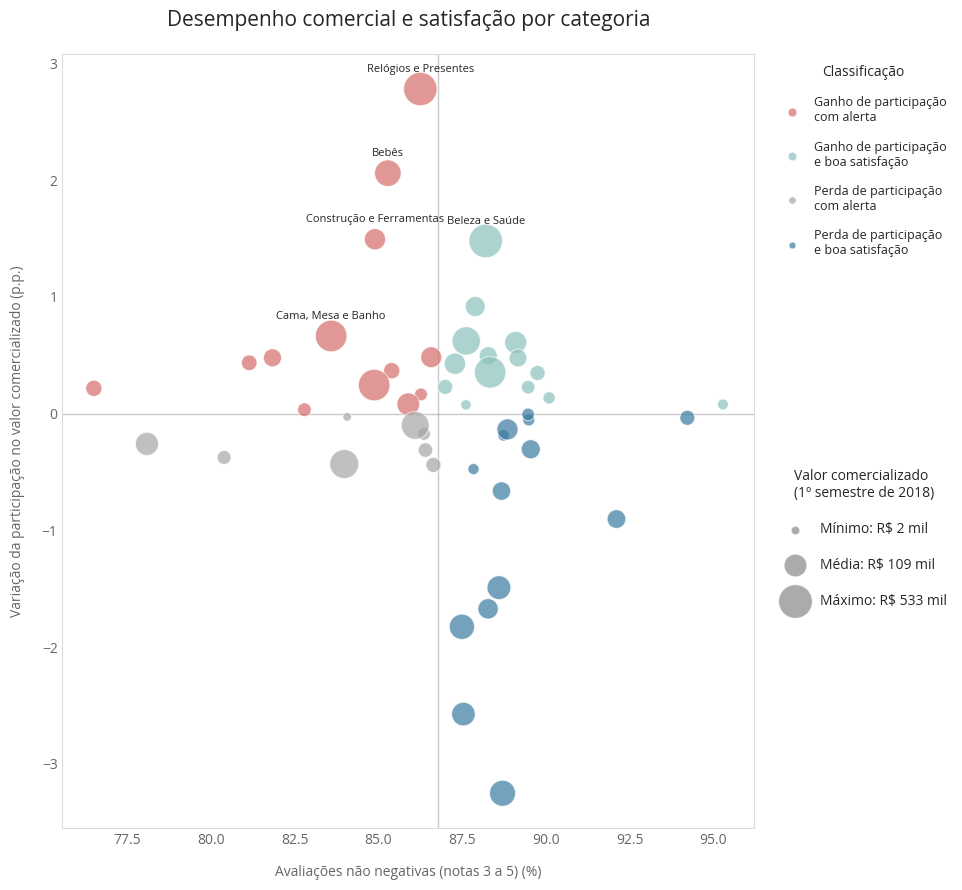

In [158]:
# Gráfico final - Matriz de desempenho comercial e alerta operacional

# Paleta visual
AZUL = '#024F7F'
TURQUESA = '#8BC1BC'
AZUL_INTERMEDIARIO = '#39799F'
CINZA = '#666666'
PRETO = '#262626'
CINZA_CLARO = '#D9DDE1'
BRANCO = '#FFFFFF'

# Cores dos quadrantes
cores_quadrantes = {
    'Ganho de participação e boa satisfação': TURQUESA,
    'Ganho de participação com alerta': '#D66B6B',
    'Perda de participação e boa satisfação': AZUL_INTERMEDIARIO,
    'Perda de participação com alerta': '#A6A6A6'
}

# Categorias destacadas nas análises anteriores
categorias_destaque = [
    'Beleza e Saúde',
    'Relógios e Presentes',
    'Bebês',
    'Cama, Mesa e Banho',
    'Construção e Ferramentas',
]

# Filtrar o primeiro semestre de 2018
base_1sem_2018 = base_analise[
    (base_analise['order_purchase_timestamp'] >= '2018-01-01') &
    (base_analise['order_purchase_timestamp'] < '2018-07-01')
].copy()

# Criar dicionário com o valor comercializado por categoria
valores_categoria = (
    base_1sem_2018
    .groupby('product_category_name_formatada')['price']
    .sum()
    .to_dict()
)

# Criar cópia independente da base do gráfico
base_grafico_v2 = base_quadrantes.copy()

# Adicionar valor comercializado por categoria
base_grafico_v2['valor_comercializado'] = (
    base_grafico_v2['product_category_name_formatada']
    .map(valores_categoria)
)

# Verificar categorias sem correspondência
if base_grafico_v2['valor_comercializado'].isna().any():
    print('Atenção: existem categorias sem valor comercializado.')

# Manter somente categorias que podem ser efetivamente desenhadas
base_grafico_v2 = base_grafico_v2.dropna(
    subset=[
        'valor_comercializado',
        'percentual_avaliacoes_nao_negativas',
        'variacao_participacao_pp'
    ]
).copy()

# Selecionar categorias que serão rotuladas
categorias_rotuladas = base_grafico_v2[
    base_grafico_v2['product_category_name_formatada'].isin(
        categorias_destaque
    )
]

# Verificar categorias destacadas que não foram encontradas
categorias_ausentes = [
    categoria for categoria in categorias_destaque
    if categoria not in categorias_rotuladas[
        'product_category_name_formatada'
    ].values
]

if categorias_ausentes:
    print('Categorias não encontradas:', categorias_ausentes)


# Gráfico

fig, ax = plt.subplots(figsize=(14, 9))

# Desenhar todas as categorias
for quadrante, grupo in base_grafico_v2.groupby('quadrante'):

    # Fórmula de tamanho das bolhas
    tamanhos = np.sqrt(grupo['valor_comercializado']) * 0.8

    ax.scatter(
        grupo['percentual_avaliacoes_nao_negativas'],
        grupo['variacao_participacao_pp'],
        s=tamanhos,
        color=cores_quadrantes[quadrante],
        alpha=0.70,
        edgecolor=BRANCO,
        linewidth=0.7,
        label=quadrante,
        zorder=3
    )


# Rótulos

for _, linha in categorias_rotuladas.iterrows():

    ax.annotate(
        linha['product_category_name_formatada'],
        (
            linha['percentual_avaliacoes_nao_negativas'],
            linha['variacao_participacao_pp']
        ),
        xytext=(0, 10),
        textcoords='offset points',
        ha='center',
        va='bottom',
        fontsize=8,
        fontweight='bold',
        color=PRETO,
        zorder=5
    )


# Divisórias dos quadrantes

ax.axvline(
    x=86.78,
    color=CINZA,
    linewidth=1,
    alpha=0.35,
    zorder=1
)

ax.axhline(
    y=0,
    color=CINZA,
    linewidth=1,
    alpha=0.35,
    zorder=1
)


# Título e Eixo

ax.set_title(
    'Desempenho comercial e satisfação por categoria',
    pad=20
)

ax.set_xlabel(
    'Avaliações não negativas (notas 3 a 5) (%)',
    labelpad=12
)

ax.set_ylabel(
    'Variação da participação no valor comercializado (p.p.)',
    labelpad=12
)


# Formatação visual

for lateral in ['top', 'right', 'left', 'bottom']:
    ax.spines[lateral].set_visible(True)
    ax.spines[lateral].set_color(CINZA_CLARO)
    ax.spines[lateral].set_linewidth(0.8)

ax.grid(False)

ax.tick_params(
    axis='both',
    length=0,
    colors=CINZA
)


# Legendas

# Criar nomes com quebra de linha para os quadrantes
nomes_quadrantes = {
    'Ganho de participação e boa satisfação':
        'Ganho de participação\ne boa satisfação',

    'Ganho de participação com alerta':
        'Ganho de participação\ncom alerta',

    'Perda de participação e boa satisfação':
        'Perda de participação\ne boa satisfação',

    'Perda de participação com alerta':
        'Perda de participação\ncom alerta'
}

# Atualizar os nomes exibidos na legenda
handles, labels = ax.get_legend_handles_labels()

labels = [
    nomes_quadrantes.get(label, label)
    for label in labels
]

legenda_quadrantes = ax.legend(
    handles,
    labels,
    title='Classificação',
    frameon=False,
    loc='upper left',
    bbox_to_anchor=(1.02, 1),
    fontsize=9,
    title_fontsize=10,
    labelspacing=1.3,
    markerscale=0.35,
    scatterpoints=1
)

ax.add_artist(legenda_quadrantes)


# Legenda do tamanho das bolhas

# Estatísticas calculadas sobre as categorias desenhadas
valores = base_grafico_v2['valor_comercializado']

valor_minimo = valores.min()
valor_medio = valores.mean()
valor_maximo = valores.max()

valores_referencia = [
    valor_minimo,
    valor_medio,
    valor_maximo
]

# Criar bolhas de referência usando a mesma fórmula aplicada às bolhas da matriz
marcadores_bolhas = []

for valor in valores_referencia:

    tamanho = np.sqrt(valor) * 0.8

    marcador = ax.scatter(
        [],
        [],
        s=tamanho,
        color=CINZA,
        alpha=0.55,
        edgecolor=BRANCO,
        linewidth=0.7
    )

    marcadores_bolhas.append(marcador)


# Rótulos da legenda
rotulos_bolhas = [
    f'Mínimo: R$ {valor_minimo / 1000:.0f} mil',
    f'Média: R$ {valor_medio / 1000:.0f} mil',
    f'Máximo: R$ {valor_maximo / 1000:.0f} mil'
]

# Legenda com escala dos marcadores
ax.legend(
    marcadores_bolhas,
    rotulos_bolhas,
    title='Valor comercializado\n(1º semestre de 2018)',
    frameon=False,
    loc='upper left',
    bbox_to_anchor=(1.02, 0.48),
    labelspacing=1.5,
    markerscale=1,
    scatterpoints=1
)


# Conferência

print('Referências das bolhas - 1º semestre de 2018:')
print(f'Mínimo: R$ {valor_minimo:,.2f}')
print(f'Média: R$ {valor_medio:,.2f}')
print(f'Máximo: R$ {valor_maximo:,.2f}')
print(f'Total de categorias desenhadas: {len(base_grafico_v2)}')


plt.tight_layout(rect=[0, 0, 0.70, 1])
plt.show()

## Considerações Finais


- O ecossistema apresentou crescimento expressivo no valor comercializado entre os primeiros semestres de 2017 e 2018, indicando expansão da atividade comercial no período analisado.
- **Beleza e Saúde** e **Relógios e Presentes** são categorias que se destacaram pelo ganho de participação no ecossistema, demonstrando avanço competitivo em relação às demais categorias.
- A categoria **Bebês** apresentou crescimento percentual acelerado e ganho de participação, embora ainda opere em uma escala comercial menor, o que exige avaliar se esse ritmo de expansão pode ser sustentado.
- **Cama, Mesa e Banho** é uma categoria que combina grande volume comercial com um percentual de avaliações negativas superior à referência do ecossistema, sinalizando um possível ponto de atenção na experiência do cliente.
- **Beleza e Saúde** é a categoria que reúne a combinação mais favorável entre ganho de participação e satisfação acima da referência, posicionando-se como a principal oportunidade de expansão entre as categorias analisadas.

### Direcionamentos Estratégicos

- **Beleza e Saúde:** priorizar a investigação de oportunidades de expansão, considerando o ganho de participação e o nível de satisfação acima da referência. A categoria apresenta o cenário mais favorável para investimentos comerciais.
- **Relógios e Presentes:** identificar oportunidades de melhoria na experiência do cliente antes de ampliar investimentos.
- **Bebês:** avaliar a sustentabilidade do crescimento e o potencial de ampliação da escala comercial, acompanhando a satisfação dos clientes para evitar que a expansão seja acompanhada pelo aumento de insatisfação.
- **Cama, Mesa e Banho:** investigar os fatores associados ao percentual elevado de avaliações negativas, priorizando ações que possam melhorar a experiência do cliente e proteger o desempenho de uma categoria de grande escala.
- **Construção e Ferramentas:** acompanhar a evolução da categoria e avaliar seu potencial de crescimento comercial. Apesar do ganho de participação, a satisfação abaixo da referência recomenda cautela antes de priorizar sua expansão.